In [1]:
from pathlib import Path
import json, torch, pandas as pd
import os

os.chdir('..')

# point to one run  ────────────────────────────────────────────────
RUN_DIR = Path("eval_results/outputs__Qwen2_5_14B_GRPO__checkpoint-1500_2025-05-27_00-08-40")

# load the JSON index  ────────────────────────────────────────────
with open(RUN_DIR / "index.json", encoding="utf-8") as fp:
    rows = json.load(fp)

df = pd.DataFrame(rows)
print("Rows:", len(df))
df.head()          # interactive preview in Jupyter


Rows: 498


,id,question,ground_answer_text,model_answers_text,extracted_model_answers,extracted_ground_answer,majority_answer,correct,output_tokens,entropy_file,forward_kl_file,layer_avg_logp_file,topk_final_log_probs_file,topk_final_ids_file,topk_final_tokens_file,topk_layer_log_probs_file,topk_layer_ids_file,topk_layer_tokens_file
0,216,\nQUESTION:\nCompute\n\[\cos^3 \frac{2 \pi}{7}...,\boxed{-\frac{1}{2}},[To solve the expression \(\cos^3 \frac{2 \pi}...,[-\frac{1}{2}],-\frac{1}{2},-\frac{1}{2},True,"[1249, 11625, 279, 7493, 1124, 11520, 9407, 61...",216_entropy.pt,216_forward_kl.pt,216_layer_avg_logp.pt,216_topk_final_log_probs.pt,216_topk_final_ids.pt,216_topk_final_tokens.pt,216_topk_layer_log_probs.pt,216_topk_layer_ids.pt,216_topk_layer_tokens.pt
1,553,\nQUESTION:\nThe matrices\n\[\mathbf{A} = \ren...,\boxed{\frac{56}{5}},[To solve for \(x + y + z\) given the matrices...,[\frac{56}{5}],\frac{56}{5},\frac{56}{5},True,"[1249, 11625, 369, 17767, 87, 488, 379, 488, 1...",553_entropy.pt,553_forward_kl.pt,553_layer_avg_logp.pt,553_topk_final_log_probs.pt,553_topk_final_ids.pt,553_topk_final_tokens.pt,553_topk_layer_log_probs.pt,553_topk_layer_ids.pt,553_topk_layer_tokens.pt
2,98,\nQUESTION:\nGiven $\|\mathbf{v}\| = 5$ and $\...,\boxed{5},[To determine the largest possible value of \(...,[5],5,5,True,"[1249, 8253, 279, 7772, 3204, 897, 315, 1124, ...",98_entropy.pt,98_forward_kl.pt,98_layer_avg_logp.pt,98_topk_final_log_probs.pt,98_topk_final_ids.pt,98_topk_final_tokens.pt,98_topk_layer_log_probs.pt,98_topk_layer_ids.pt,98_topk_layer_tokens.pt
3,287,"\nQUESTION:\nIn triangle $ABC,$ $\angle C = 90...",\boxed{\frac{\sqrt{6}}{3}},[To solve for \(\sin \angle BAC\) given that \...,[\frac{\sqrt{3}}{3}],\frac{\sqrt{6}}{3},\frac{\sqrt{3}}{3},False,"[1249, 11625, 369, 1124, 11520, 15940, 1124, 4...",287_entropy.pt,287_forward_kl.pt,287_layer_avg_logp.pt,287_topk_final_log_probs.pt,287_topk_final_ids.pt,287_topk_final_tokens.pt,287_topk_layer_log_probs.pt,287_topk_layer_ids.pt,287_topk_layer_tokens.pt
4,356,\nQUESTION:\nThe set of vectors $\mathbf{v}$ s...,\boxed{y = -2x},[To determine the equation of the line on whic...,[y = -2x],y = -2x,y = -2x,True,"[1249, 8253, 279, 23606, 315, 279, 1555, 389, ...",356_entropy.pt,356_forward_kl.pt,356_layer_avg_logp.pt,356_topk_final_log_probs.pt,356_topk_final_ids.pt,356_topk_final_tokens.pt,356_topk_layer_log_probs.pt,356_topk_layer_ids.pt,356_topk_layer_tokens.pt


In [2]:
# all wrong answers
wrong = df[~df.correct]
wrong[["id", "question", "model_answers_text"]].head()


,id,question,model_answers_text
3,287,"\nQUESTION:\nIn triangle $ABC,$ $\angle C = 90...",[To solve for \(\sin \angle BAC\) given that \...
5,1119,\nQUESTION:\nThere exist two complex numbers $...,[To solve for the product \(c_1 c_2\) where \(...
12,820,\nQUESTION:\nFor a positive integer $n$ and an...,"[To solve the problem, we need to analyze the ..."
15,412,\nQUESTION:\nGiven that\n\[\begin{vmatrix} a &...,"[To solve the given problem, we need to evalua..."
16,716,\nQUESTION:\nA line intersects the $yz$-plane ...,[To find the point where the line intersects t...


In [3]:
row = wrong.iloc[0]          # pick first mistake

# helper for shorter syntax
load = lambda key: torch.load(RUN_DIR / row[f"{key}_file"], weights_only=False)

topk_lp    = load("topk_final_log_probs")   # (seq_len , K)
topk_ids   = load("topk_final_ids")         # (seq_len , K)
topk_toks  = load("topk_final_tokens")      # list[list[str]]
entropy    = load("entropy")                # (n_layers , seq_len)

print("Question:", row.question[:120], "…")
print("Model answer:", row.model_answers_text[0])
print("Log-probs shape :", topk_lp.shape)
print("Top-5 tokens @ first position:", topk_toks[0])


Question: 
QUESTION:
In triangle $ABC,$ $\angle C = 90^\circ$ and $M$ is the midpoint of $\overline{BC}.$  If $\sin \angle BAM = \ …
Model answer: To solve for \(\sin \angle BAC\) given that \(\sin \angle BAM = \frac{1}{3}\) in right triangle \(ABC\) with \(\angle C = 90^\circ\) and \(M\) as the midpoint of \(\overline{BC}\), we proceed as follows:

1. **Identify key points and relationships**:
   - Let \( \angle BAC = \theta \).
   - Since \( M \) is the midpoint of \( \overline{BC} \), we have \( BM = MC \).

2. **Set up coordinates for convenience**:
   - Place point \(C\) at the origin \((0, 0)\).
   - Point \(A\) at \((a, 0)\).
   - Point \(B\) at \((0, b)\).

3. **Calculate the coordinates of \(M\)**:
   - Since \(M\) is the midpoint of \(\overline{BC}\), its coordinates are \(\left(0, \frac{b}{2}\right)\).

4. **Express trigonometric functions**:
   - In \(\triangle ABM\), the sine of \(\angle BAM\) is given by \(\sin \angle BAM = \frac{\text{opposite}}{\text{hypotenuse}}\). 
  

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-14B")

decoded_first_pos = tok.convert_ids_to_tokens(topk_ids[0].tolist())


/datassd/home/plazaro/.conda/envs/qwen-tunedlens-math/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
for _, r in df[~df.correct].iterrows():
    ids   = torch.load(RUN_DIR / r["topk_final_ids_file"])
    toks  = torch.load(RUN_DIR / r["topk_final_tokens_file"])
    print("Problem", r.id)
    print(" → top-1 guess sequence :", [t[0] for t in toks[:10]])  # first 10 positions
    print()


Problem 287
 → top-1 guess sequence : ['Ġsolve', 'Ġfor', 'Ġ\\', '(\\', 'sin', 'Ġ\\', 'angle', 'ĠB', 'AC', '\\)']

Problem 1119
 → top-1 guess sequence : ['Ġsolve', 'Ġfor', 'Ġthe', 'Ġproduct', 'Ġ\\(', 'c', '_', '1', 'Ġc', '_']

Problem 820
 → top-1 guess sequence : ['Ġsolve', 'Ġthe', 'Ġproblem', ',', 'Ġwe', 'Ġneed', 'Ġto', 'Ġanalyze', 'Ġthe', 'Ġconditions']

Problem 412
 → top-1 guess sequence : ['Ġsolve', 'Ġthe', 'Ġproblem', 'Ġproblem', ',', 'Ġwe', 'Ġneed', 'Ġto', 'Ġevaluate', 'Ġthe']

Problem 716
 → top-1 guess sequence : ['Ġfind', 'Ġthe', 'Ġpoint', 'Ġwhere', 'Ġthe', 'Ġline', 'Ġintersects', 'Ġthe', 'Ġ$', 'xy']

Problem 612
 → top-1 guess sequence : ['Ġfind', 'Ġthe', 'Ġradius', 'Ġof', 'Ġthe', 'Ġsphere', 'Ġins', 'cribed', 'Ġin', 'Ġthe']

Problem 649
 → top-1 guess sequence : ['Ġsolve', 'Ġ\\', '(\\', 'cos', '^', '2', 'Ġ\\', 'angle', 'ĠG', 'OM']

Problem 1312
 → top-1 guess sequence : ['Ġfind', 'Ġthe', 'Ġprojection', 'Ġof', 'Ġvector', 'Ġvector', 'Ġ$\\', 'math', 'bf', '{']

Problem 1056
 →

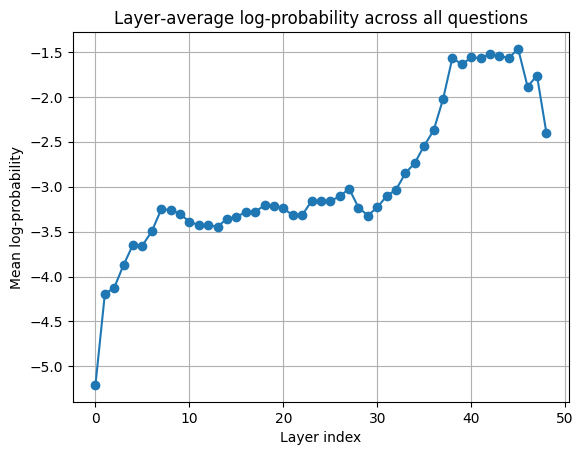

In [6]:
import matplotlib.pyplot as plt
import numpy as np

correct_rows = [r for r in rows if r.get("correct")]

# ─── gather every layer‑average vector ───────────────────────────────
layer_rows = []
for row in correct_rows:
    fname_key = "layer_avg_logp_file"
    if fname_key in row:                      # skip rows without the blob
        vec = torch.load(RUN_DIR / row[fname_key], map_location="cpu")
        # vec is either a 1‑D tensor or NumPy array
        layer_rows.append(np.asarray(vec))

if not layer_rows:
    raise ValueError("No layer_avg_logp_file entries found. Check your RUN_DIR.")

layer_matrix = np.stack(layer_rows)           # shape = (n_questions , n_layers)
mean_logp    = layer_matrix.mean(axis=0)      # (n_layers,)

# ─── plot ────────────────────────────────────────────────────────────
plt.figure()
plt.plot(range(len(mean_logp)), mean_logp, marker="o")  # default colours
plt.xlabel("Layer index")
plt.ylabel("Mean log‑probability")
plt.title("Layer‑average log‑probability across all questions")
plt.grid(True)
plt.show()

### OJO, QUE CABE LA POSIBILIDAD DE QUE AL SER EQUIV, NO SEA EXACTAMTNE EL MISMO RESULTADO EN TOKENS

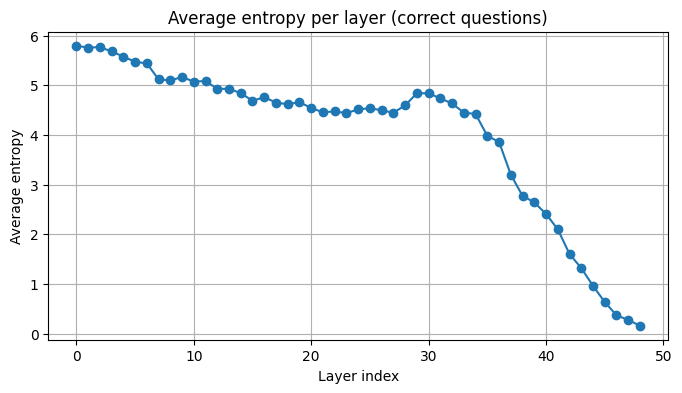

In [11]:
# ─── Filter to correctly answered questions ───────────────────────
correct_rows = [r for r in rows if r.get("correct")]

# ─── Gather, collapse, and average each question’s entropy ─────────
layer_vectors = []
for r in correct_rows:
    fname = r.get("entropy_file")
    if not fname:
        continue
    blob = torch.load(RUN_DIR / fname, map_location="cpu", weights_only=False)
    # unwrap dict if needed
    tensor = blob["entropy"] if isinstance(blob, dict) and "entropy" in blob else blob
    arr = tensor                     # e.g. shape (n_layers, seq_len) or (n_layers,)

    # if there's a token dimension, average it out
    if arr.ndim == 2:
        arr = arr.mean(axis=1)                      # now shape (n_layers,)
    elif arr.ndim > 2:
        # flatten any extra dims then average
        arr = arr.reshape(arr.shape[0], -1).mean(axis=1)

    layer_vectors.append(arr)

if not layer_vectors:
    raise RuntimeError("No entropy data found for correct questions.")

# ─── Stack & compute mean across questions ───────────────────────
matrix       = np.stack(layer_vectors)            # (n_correct, n_layers)
mean_entropy = matrix.mean(axis=0)               # (n_layers,)

# ─── Plot ───────────────────────────────────────────────────────
plt.figure(figsize=(8, 4))
plt.plot(np.arange(len(mean_entropy)), mean_entropy, marker='o')
plt.xlabel("Layer index")
plt.ylabel("Average entropy")
plt.title("Average entropy per layer (correct questions)")
plt.grid(True)
plt.show()